In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

---

if $f$ is on $N \times N \times N$ and downsample factor of $s$: </br>

$$ f'_{i,j,k} = \frac {1}{s^3} \sum_{a=0}^{s-1} \sum_{b=0}^{s-1} \sum_{c=0}^{s-1} f_{si + a, sj + b, sk + c} $$ </br>

---

In [2]:
vol_a_file = 'Data/het_models/0.mrc'
vol_b_file = 'Data/het_models/0.mrc'

with mrcfile.open(vol_a_file, permissive=True) as mrc:
    f = mrc.data
    dx_f = mrc.voxel_size.x  # voxels are 1x1x1
    mrc.close

with mrcfile.open(vol_b_file, permissive=True) as mrc:
    g = mrc.data
    dx_g = mrc.voxel_size.x
    mrc.close   

print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

t = time.time()
s = 2  # integer scale factor for downsample
f = transforms.block_average_downsample(f, s) 
g = transforms.block_average_downsample(g, s) 
print("downsample time: ", time.time() - t, '\n')

ds = dx_f*s
dV = (ds)**3

# f = np.pad(f, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size
# g = np.pad(g, pad_width=((0, 1), (0, 1), (0, 1)))  

f = signals.Signal(f, d=3, dx=ds).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=ds).preprocess_signals()[0]

 

print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

(128, 128, 128)
0.0 0.43591255 1025.7806
0.0 0.43591255 1025.7806


downsample time:  0.043518781661987305 

(64, 64, 64)
0.0 0.00035347196 0.125
0.0 0.00035347196 0.125




/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


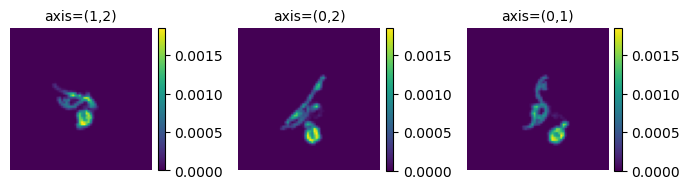

(64, 64, 64)
1.0


In [3]:
plots.orthogonal_2D_projection_plot(f)

print(f.shape)
print( np.sum(f) * dV )

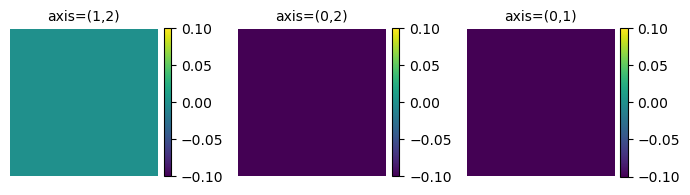

In [4]:
### EV: rotations without interpolation
# g = g[::-1, :, ::-1]  
# g = np.rot90(g)

plots.orthogonal_2D_projection_plot(f - g)

In [5]:
N = f.shape[0]
M = f.shape[0]   # grid size LxLxL
d = 3            # dimensons
max_l = M//2

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

In [6]:
# c = alignments.align_l2(np.flip(f, axis=2), np.flip(f, axis=2), fle).real 

c = alignments.align_l2(np.flip(f, axis=2), np.flip(g, axis=2), fle).real 

evaluate_t, step 1:  0.9932467937469482
step 2:  2.703331232070923
everything else:  0.9627468585968018


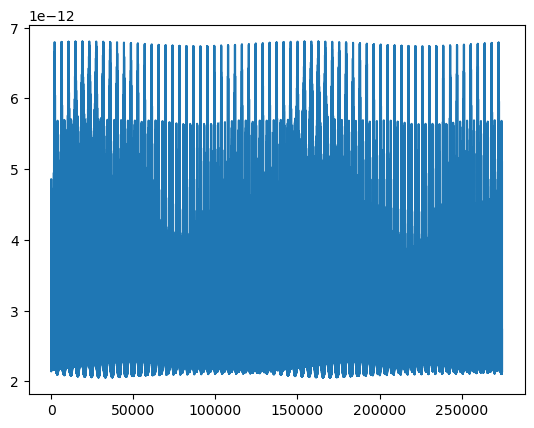

In [7]:
plt.plot( c.flatten() )
# plt.plot(c[:, :, 0].flatten())

---

Approximation of inner product of $f$, $g$ :

$$ \langle f, g \rangle = \iiint f(x,y,z) g(x,y,z) dV $$ </br>

$$ \langle f, g \rangle \approx \sum_{i,j,k} f_{ijk} g_{ijk} \Delta V $$

<!-- and for the distance: </br>



$$
\begin{align}
\| f - g \|^2 &= \int (f - g)^2 dV \\
&= \int f^2 dV + \int g^2 dV - 2\int fg \,dV \\
&\approx \Delta V \left( \sum f^2_{ijk} + \sum g^2_{ijk} - 2 \sum f_{ijk} g_{ijk} \right)
\end{align}
$$

</br>

- but this part doesn't really matter because it's just global scaling? </br>
- looking for the differences between np.sum(f * g) and FRM </br>
- or does including dV change scaling in RT -> slice distance??? </br>
- need to consider it's spherical for FRM volume element? </br>
- *note that we already have a constant for the 3D Radon transform* -->

---

In [8]:
print(" gt corr: ", np.sum(f * g) * dV)

print("est corr: ", np.amax(c) * dV)

 gt corr:  0.0001859183539636433
est corr:  5.4451000506480594e-11


In [9]:
### as distance
# np.linalg.norm(f - g)**2

np.linalg.norm(f)**2 + np.linalg.norm(g)**2 - 2*np.sum(f * g)

6.701438449302488e-12

In [10]:
print(" ||f||^2 :", np.linalg.norm(f)**2)
print(" ||g||^2 :", np.linalg.norm(g)**2)
print(" <f, g>  :", np.sum(f * g))

 ||f||^2 : 2.323979759617464e-05
 ||g||^2 : 2.323979759617464e-05
 <f, g>  : 2.3239794e-05


In [11]:
### this should be approximately zero ?

dists = (np.linalg.norm(f)**2 + np.linalg.norm(g)**2 - 2*c) * dV

np.amin(dists)

0.0003718366526367932

In [12]:
### I think this is the value we want to match from FRM

np.sum(f * g) 

2.3239794e-05

In [13]:
### if just comparing correlation, should look at the maximum

np.amax( c * N**3 ) #* 4*np.pi    ### 4pi makes it approx equal for f = g ?

1.7842503845963561e-06

In [14]:
f_rt = transforms.Transform(f, d=3).radon_transform()[0]

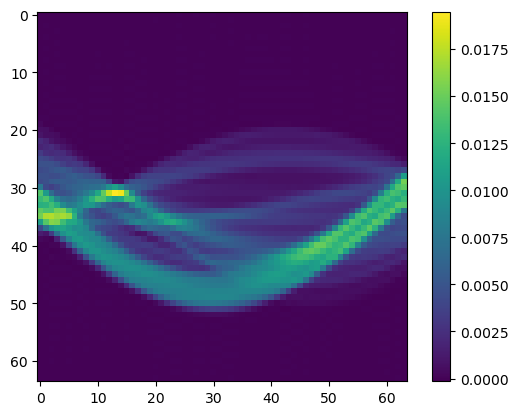

In [15]:
plt.imshow(f_rt[0])
plt.colorbar()
plt.show()

In [16]:
# np.sum(f_rt[0, :, 0]) * (((2 - 2/N)**2) / (N**2))**-1
# np.sum(f_rt[0, :, 0]) * ( N**2 / (2 - 2/N)**2 )

In [17]:
### EV: if I remove the normalization from the transforms.py script
###     then the projections match if I do np.sum(f) * dA / 4 [... but why divide by 4]
###     or equivalently if I multiply dV instead of dA ?

---


<!-- $$ \iint_{\mathbb{R}^2} f( R_{\theta , \varphi}^\top} (x,y,z) )dxdydz $$ -->

$$ \iint_{\mathbb{R}^2} f( R^\top_{\theta , \varphi} (x,y,z)  )dxdy   $$

---

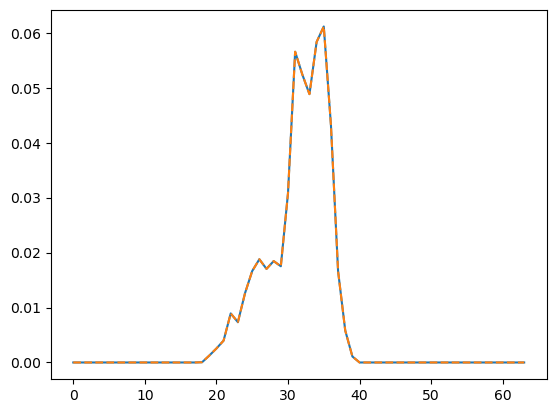

In [18]:
dA = ds**2
# dA = 1

plt.plot( f_rt[0, :, 0] * dA  )

plt.plot( np.sum(f, axis=(0,1)) * dA, '--' )

In [19]:
np.sum( np.sum(f, axis=(0,1)) * ds**2 ) * ds

0.9999999403953552